# DriveGuard Lane State Analysis v4

## 프로젝트 목표

블랙박스 원본 영상에서 차선을 직접 검출하고, 차선 상태와 영상 기반 상대 주행 속도를 함께 분석한다.

- 현재 주행 차로의 좌·우 차선 검출
- 차선 중심 오차 및 이탈 여부 판단
- 진행 방향과 좌·우 여유 폭 분석
- Optical Flow 기반 상대 속도 상태 추정
- 위험 단계와 주의사항을 한글 오버레이로 표시

> 상대 속도는 GPS 기반 km/h가 아니라 프레임 간 영상 움직임으로 계산한 `정지 / 저속 / 보통 / 고속` 수준의 추정값이다.


## 1. 프로젝트 경로 설정

현재 노트북 위치를 기준으로 `DriveGuard` 프로젝트 루트와  
기존 자율주행 코드가 들어 있는 `ros3_ws` 경로를 설정한다.

In [1]:
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from collections import deque

DISPLAY_CROP_TOP_RATIO = 0.22

OFFSET_HISTORY = deque(maxlen=7)
HEADING_HISTORY = deque(maxlen=7)

print("Python:", sys.version)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("DriveGuard v5 notebook ready")

Python: 3.10.20 | packaged by Anaconda, Inc. | (main, Jun 11 2026, 15:13:20) [MSC v.1942 64 bit (AMD64)]
OpenCV: 5.0.0
NumPy: 2.2.6
Pandas: 2.3.3
DriveGuard v5 notebook ready


## 2. 기존 라이브러리 경로 등록

`ros3_ws` 내부의 카메라 인지 및 판단·경로계획 라이브러리 위치를 찾고,  
해당 경로를 Python 모듈 검색 경로에 추가한다.

In [2]:
from pathlib import Path
import sys

# 현재 노트북 위치:
# DriveGuard/notebooks/lane_state_analysis.ipynb
NOTEBOOK_DIR = Path.cwd().resolve()

# 노트북을 notebooks 폴더에서 실행한다고 가정
PROJECT_ROOT = NOTEBOOK_DIR.parent
ROS_ROOT = PROJECT_ROOT / "ros3_ws"

print("노트북 위치:", NOTEBOOK_DIR)
print("프로젝트 위치:", PROJECT_ROOT)
print("ros3_ws 위치:", ROS_ROOT)
print("ros3_ws 존재:", ROS_ROOT.exists())

노트북 위치: C:\Users\shine\DriveGuard\notebooks
프로젝트 위치: C:\Users\shine\DriveGuard
ros3_ws 위치: C:\Users\shine\DriveGuard\ros3_ws
ros3_ws 존재: True


## 3. 기존 인지·판단 함수 불러오기

수업에서 사용한 카메라 인지 함수와 판단·경로계획 함수를 import한다.  
이후 차선 검출, 차선 중심 계산, 경로 기울기 계산에 재사용한다.

In [3]:
CAM_LIB = (
    ROS_ROOT
    / "src"
    / "camera_perception_pkg"
    / "camera_perception_pkg"
    / "lib"
)

DEC_LIB = (
    ROS_ROOT
    / "src"
    / "decision_making_pkg"
    / "decision_making_pkg"
    / "lib"
)

SAMPLES = (
    CAM_LIB
    / "Collected_Datasets"
    / "sample_dataset"
)

for path in [CAM_LIB, DEC_LIB]:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

print("CAM_LIB 존재:", CAM_LIB.exists())
print("DEC_LIB 존재:", DEC_LIB.exists())
print("SAMPLES 존재:", SAMPLES.exists())

CAM_LIB 존재: True
DEC_LIB 존재: True
SAMPLES 존재: True


## 4. 핵심 함수 사용 가능 여부 확인

프로젝트에서 사용할 주요 함수들이 정상적으로 불러와졌는지 확인한다.

In [4]:
import camera_perception_func_lib as cam
import decision_making_function_lib as dm

print("카메라 인지 함수 로드 완료")
print("판단·경로계획 함수 로드 완료")


 ____    ___   ____    ____  
|  _ \  / _ \ / ___|  |___ \ 
| |_) || | | |\___ \    __) |
|  _ < | |_| | ___) |  / __/ 
|_| \_\ \___/ |____/  |_____|
                             
    _            _                 
   / \    _   _ | |_   ___         
  / _ \  | | | || __| / _ \  _____ 
 / ___ \ | |_| || |_ | (_) ||_____|
/_/   \_\ \__,_| \__| \___/        
                                   
__     __       _      _        _       
\ \   / /  ___ | |__  (_)  ___ | |  ___ 
 \ \ / /  / _ \| '_ \ | | / __|| | / _   \ V /  |  __/| | | || || (__ | ||  __/
   \_/    \___||_| |_||_| \___||_| \___|  


ROS2 기반 자율주행 설계 및 구현
Sungkyunkwan University Automation Lab.
------------------Authors------------------
Hyeong-Keun Hong <whaihong@g.skku.edu>
Jinsun Lee <with23skku@g.skku.edu>
Siwoo Lee <edenlee@g.skku.edu>
Jae-Wook Jeon <jwjeon@skku.edu>
------------------------------------------

 ____    ___   ____    ____  
|  _ \  / _ \ / ___|  |___ \ 
| |_) || | | |\___ \    __) |
|  _ < | |_| | ___) 

In [5]:
functions_to_check = {
    "bird_convert": cam.bird_convert,
    "roi_rectangle_below": cam.roi_rectangle_below,
    "dominant_gradient": cam.dominant_gradient,
    "get_lane_center": cam.get_lane_center,
    "calculate_slope_between_points": dm.calculate_slope_between_points,
}

for name, func in functions_to_check.items():
    print(f"{name}: {callable(func)}")

bird_convert: True
roi_rectangle_below: True
dominant_gradient: True
get_lane_center: True
calculate_slope_between_points: True


## 5. 샘플 이미지 불러오기

기존 실습 데이터의 `sample01.png`를 불러와 원본 영상이 정상적으로 읽히는지 확인한다.

이미지 경로: C:\Users\shine\DriveGuard\ros3_ws\src\camera_perception_pkg\camera_perception_pkg\lib\Collected_Datasets\sample_dataset\sample01.png
이미지 크기: (480, 640, 3)


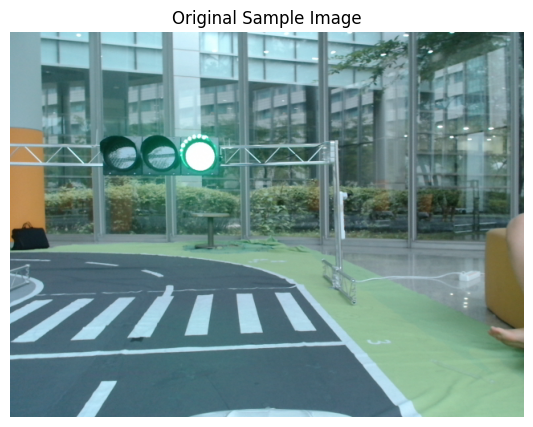

In [6]:
sample_path = SAMPLES / "sample01.png"

img = cv2.imread(str(sample_path))

if img is None:
    raise FileNotFoundError(f"이미지를 불러오지 못했습니다: {sample_path}")

print("이미지 경로:", sample_path)
print("이미지 크기:", img.shape)

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Sample Image")
plt.axis("off")
plt.show()

## 6. 원근 변환(BEV)

블랙박스 시점의 도로 영상을 위에서 내려다본 형태로 변환한다.  
차선의 위치와 폭을 계산하기 쉽게 만드는 단계이다.

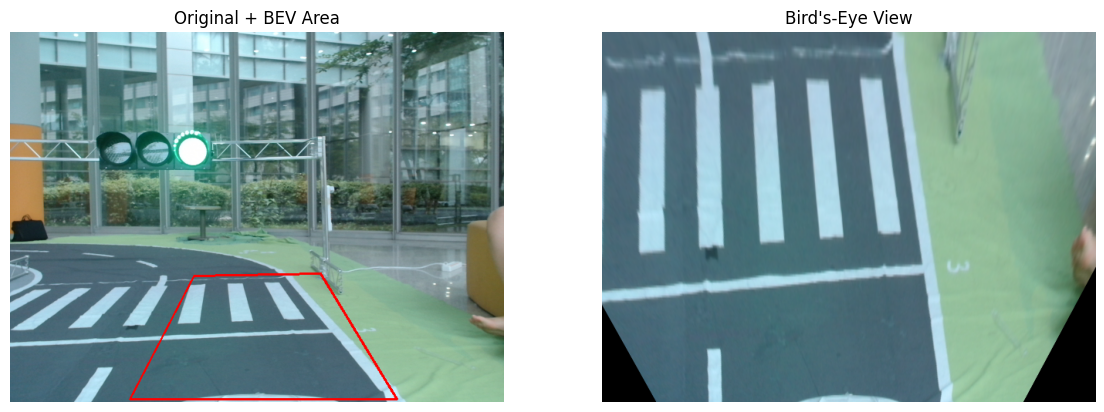

In [7]:
h, w = img.shape[:2]

src_mat = [
    [238, 316],
    [402, 313],
    [501, 476],
    [155, 476],
]

dst_mat = [
    [round(w * 0.3), 0],
    [round(w * 0.7), 0],
    [round(w * 0.7), h],
    [round(w * 0.3), h],
]

bev = cam.bird_convert(
    img,
    srcmat=src_mat,
    dstmat=dst_mat,
)

vis_src = img.copy()
cv2.polylines(
    vis_src,
    [np.int32(src_mat)],
    True,
    (0, 0, 255),
    2,
)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(vis_src, cv2.COLOR_BGR2RGB))
plt.title("Original + BEV Area")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(bev, cv2.COLOR_BGR2RGB))
plt.title("Bird's-Eye View")
plt.axis("off")

plt.show()

## 7. 관심영역(ROI) 추출

BEV 영상에서 차량과 가까운 도로 영역만 남긴다.  
차선 분석에 불필요한 위쪽 영역을 제거한다.

BEV 크기: (480, 640, 3)
ROI 크기: (180, 640, 3)


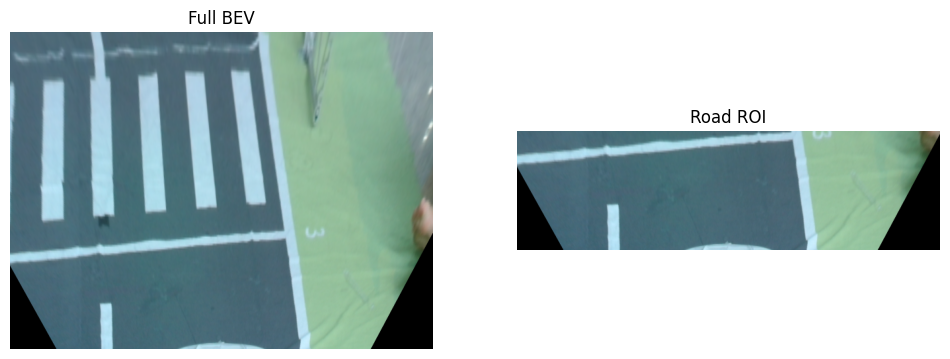

In [8]:
roi = cam.roi_rectangle_below(
    bev,
    cutting_idx=300,
)

print("BEV 크기:", bev.shape)
print("ROI 크기:", roi.shape)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(bev, cv2.COLOR_BGR2RGB))
plt.title("Full BEV")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
plt.title("Road ROI")
plt.axis("off")

plt.show()

## 8. 차선 이진 마스크 생성

ROI 영상을 흑백으로 변환하고 밝은 차선 영역만 추출한다.  
기존 실습에서는 실제 YOLO 차선 세그멘테이션 출력 대신 임계값 기반 이진화를 사용한다.

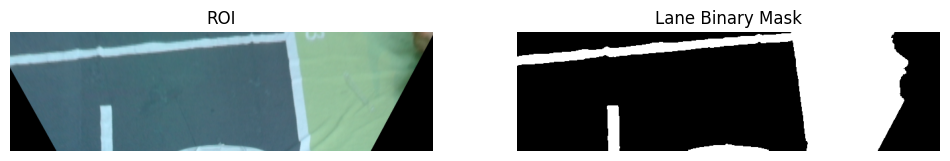

In [9]:
gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)

_, lane_mask = cv2.threshold(
    gray,
    150,
    255,
    cv2.THRESH_BINARY,
)

kernel = np.ones((3, 3), np.uint8)

lane_mask = cv2.morphologyEx(
    lane_mask,
    cv2.MORPH_OPEN,
    kernel,
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
plt.title("ROI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lane_mask, cmap="gray")
plt.title("Lane Binary Mask")
plt.axis("off")

plt.show()

## 9. 차선 대표 기울기 계산

이진 차선 이미지에서 Hough 기반 대표 기울기를 계산한다.  
양수는 오른쪽, 음수는 왼쪽으로 기울어진 방향을 의미한다.

In [10]:
angle = cam.dominant_gradient(
    lane_mask,
    theta_limit=45,
)

print(f"차선 대표 기울기: {angle:.2f}°")

차선 대표 기울기: 1.00°


## 10. 차선 중심 좌표 계산

특정 높이의 차선 픽셀을 이용해 차량이 향해야 할 목표 차선 중심의 x좌표를 계산한다.

In [11]:
mask_h, mask_w = lane_mask.shape[:2]

center_x = cam.get_lane_center(
    lane_mask,
    detection_height=mask_h // 2,
    detection_thickness=10,
    road_gradient=angle,
    lane_width=mask_w,
)

print(f"목표 차선 중심 x: {center_x:.1f}")
print(f"영상 중심 x: {mask_w / 2:.1f}")

목표 차선 중심 x: 639.0
영상 중심 x: 320.0


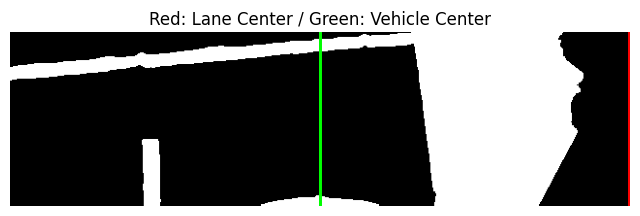

In [12]:
lane_vis = cv2.cvtColor(lane_mask, cv2.COLOR_GRAY2BGR)

# 검출된 차선 중심
cv2.line(
    lane_vis,
    (int(center_x), 0),
    (int(center_x), mask_h),
    (0, 0, 255),
    2,
)

# 영상 중심
cv2.line(
    lane_vis,
    (mask_w // 2, 0),
    (mask_w // 2, mask_h),
    (0, 255, 0),
    2,
)

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(lane_vis, cv2.COLOR_BGR2RGB))
plt.title("Red: Lane Center / Green: Vehicle Center")
plt.axis("off")
plt.show()

## 11. 차선 중심 오차 계산

검출된 차선 중심과 차량 기준 중심의 차이를 계산한다.

- `offset_px = 차선 중심 - 차량 중심`
- 음수: 차선 중심이 차량보다 왼쪽에 있음
- 양수: 차선 중심이 차량보다 오른쪽에 있음

해상도 변화에 대응하기 위해 픽셀값뿐 아니라 영상 폭 대비 비율도 계산한다.

In [13]:
def calculate_lane_offset(
    center_x,
    vehicle_center_x,
    lane_width_px,
):
    """
    차선 중심과 차량 중심의 차이를 차선 폭 기준으로 계산한다.
    """

    if lane_width_px is None or lane_width_px <= 0:
        return {
            "vehicle_center_x": float(vehicle_center_x),
            "lane_center_x": None,
            "offset_px": None,
            "offset_ratio": None,
        }

    offset_px = float(center_x - vehicle_center_x)

    # 영상 전체 폭이 아니라 실제 차선 폭으로 정규화
    offset_ratio = offset_px / lane_width_px

    return {
        "vehicle_center_x": float(vehicle_center_x),
        "lane_center_x": float(center_x),
        "offset_px": offset_px,
        "offset_ratio": offset_ratio,
    }

## 12. 차선 이탈 상태 판단

중심 오차 비율을 이용해 차량 상태를 다음 단계로 분류한다.

- `NORMAL`: 차선 중앙 부근
- `LEFT_WARNING`, `RIGHT_WARNING`: 한쪽 차선에 가까워지는 상태
- `LEFT_DEPARTURE`, `RIGHT_DEPARTURE`: 차선 이탈 위험 상태

임계값은 영상 폭에 대한 비율로 설정하며, 이후 실제 영상 결과를 보면서 조정한다.

In [14]:
def determine_departure_status(
    offset_ratio,
    warning_threshold=0.10,
    departure_threshold=0.25,
):
    """
    차선 폭 대비 중심 편향 비율로 이탈 상태를 판단한다.
    """

    if offset_ratio is None:
        return "LANE_UNCERTAIN"

    abs_offset = abs(offset_ratio)

    if abs_offset < warning_threshold:
        return "NORMAL"

    # 차선 중심이 차량 오른쪽에 있음
    # → 차량은 차로 왼쪽에 치우침
    if offset_ratio > 0:
        if abs_offset < departure_threshold:
            return "LEFT_WARNING"
        return "LEFT_DEPARTURE"

    # 차선 중심이 차량 왼쪽에 있음
    # → 차량은 차로 오른쪽에 치우침
    if abs_offset < departure_threshold:
        return "RIGHT_WARNING"

    return "RIGHT_DEPARTURE"

## 13. 차량 진행 방향 판단

차선 영상에서 계산된 대표 기울기를 이용해 차량의 예상 진행 방향을 판단한다.

- 각도가 0도 부근: 직진
- 음의 각도: 왼쪽 방향
- 양의 각도: 오른쪽 방향

이 값은 실제 차체 자세각이 아니라 영상의 차선 방향을 기준으로 추정한 진행 방향각이다.

In [15]:
def determine_heading_status(
    heading_angle_deg,
    straight_threshold=3.0,
    sharp_threshold=12.0,
):
    """
    차선 대표 기울기를 이용해 진행 방향을 판단한다.

    Parameters
    ----------
    heading_angle_deg : float
        차선 또는 경로의 대표 기울기
    straight_threshold : float
        직진으로 판단할 각도 범위
    sharp_threshold : float
        큰 방향 변화로 판단할 각도 기준

    Returns
    -------
    str
        진행 방향 상태
    """
    angle = float(heading_angle_deg)

    if abs(angle) < straight_threshold:
        return "STRAIGHT"

    if angle < 0:
        if abs(angle) >= sharp_threshold:
            return "SHARP_LEFT"
        return "LEFT"

    if abs(angle) >= sharp_threshold:
        return "SHARP_RIGHT"

    return "RIGHT"


heading_angle_deg = float(angle)

heading_status = determine_heading_status(
    heading_angle_deg
)

print(f"진행 방향각: {heading_angle_deg:.2f}°")
print("진행 방향:", heading_status)

진행 방향각: 1.00°
진행 방향: STRAIGHT


보충

## 14. 좌우 차선 여유 폭 분석

차량 기준 중심을 기준으로 가장 가까운 왼쪽·오른쪽 차선 위치를 찾는다.

검출된 차선 사이의 전체 폭과 차량 양옆의 여유 폭을 계산하여 다음 상태를 판단한다.

- `CENTERED`: 차선 중앙 부근
- `TOO_CLOSE_LEFT`: 왼쪽 차선에 근접
- `TOO_CLOSE_RIGHT`: 오른쪽 차선에 근접
- `OUT_OF_LANE`: 차선 바깥으로 이탈
- `LANE_UNCERTAIN`: 차선 검출 실패

In [16]:
def analyze_lane_margins(
    lane_mask,
    vehicle_center_x,
    reference_y=None,
    band_height=20,
    close_threshold=0.25,
    centered_tolerance=0.10,
):
    """
    차선 마스크에서 차량 좌우의 차선 위치와 여유 폭을 계산한다.

    Parameters
    ----------
    lane_mask : np.ndarray
        차선이 흰색으로 표현된 이진 이미지
    vehicle_center_x : float
        차량 기준 중심의 x 좌표
    reference_y : int or None
        차선 폭을 측정할 기준 y 좌표
    band_height : int
        한 줄이 아닌 일정 높이 구간을 함께 분석
    close_threshold : float
        한쪽 여유 비율이 이 값보다 작으면 차선 근접 상태
    centered_tolerance : float
        좌우 여유 비율 차이가 이 값보다 작으면 중앙 상태

    Returns
    -------
    dict
        좌우 차선 위치, 여유 폭, 여유 비율, 차량 위치 상태
    """
    if lane_mask.ndim != 2:
        raise ValueError("lane_mask는 흑백 이진 이미지여야 합니다.")

    h, w = lane_mask.shape

    if reference_y is None:
        reference_y = h // 2

    reference_y = int(np.clip(reference_y, 0, h - 1))

    y_start = max(0, reference_y - band_height // 2)
    y_end = min(h, reference_y + band_height // 2 + 1)

    # 기준 높이 주변의 차선 픽셀을 세로 방향으로 누적
    band = lane_mask[y_start:y_end, :]
    column_counts = np.count_nonzero(band > 0, axis=0)

    # 분석 구간 높이의 30% 이상 흰색인 열만 차선 후보로 사용
    minimum_count = max(1, int((y_end - y_start) * 0.30))
    candidate_x = np.where(column_counts >= minimum_count)[0]

    left_candidates = candidate_x[candidate_x < vehicle_center_x]
    right_candidates = candidate_x[candidate_x > vehicle_center_x]

    if len(left_candidates) == 0 or len(right_candidates) == 0:
        return {
            "left_lane_x": None,
            "right_lane_x": None,
            "lane_width_px": None,
            "left_margin_px": None,
            "right_margin_px": None,
            "left_margin_ratio": None,
            "right_margin_ratio": None,
            "position_status": "LANE_UNCERTAIN",
            "reference_y": reference_y,
        }

    # 차량 중심에서 가장 가까운 좌우 차선 선택
    left_lane_x = float(left_candidates.max())
    right_lane_x = float(right_candidates.min())

    lane_width_px = right_lane_x - left_lane_x
    left_margin_px = vehicle_center_x - left_lane_x
    right_margin_px = right_lane_x - vehicle_center_x

    if lane_width_px <= 0:
        position_status = "LANE_UNCERTAIN"
        left_margin_ratio = None
        right_margin_ratio = None

    else:
        left_margin_ratio = left_margin_px / lane_width_px
        right_margin_ratio = right_margin_px / lane_width_px

        if left_margin_px <= 0 or right_margin_px <= 0:
            position_status = "OUT_OF_LANE"

        elif left_margin_ratio < close_threshold:
            position_status = "TOO_CLOSE_LEFT"

        elif right_margin_ratio < close_threshold:
            position_status = "TOO_CLOSE_RIGHT"

        elif abs(left_margin_ratio - right_margin_ratio) <= centered_tolerance:
            position_status = "CENTERED"

        elif left_margin_ratio < right_margin_ratio:
            position_status = "LEFT_BIASED"

        else:
            position_status = "RIGHT_BIASED"

    return {
        "left_lane_x": left_lane_x,
        "right_lane_x": right_lane_x,
        "lane_width_px": lane_width_px,
        "left_margin_px": left_margin_px,
        "right_margin_px": right_margin_px,
        "left_margin_ratio": left_margin_ratio,
        "right_margin_ratio": right_margin_ratio,
        "position_status": position_status,
        "reference_y": reference_y,
    }


margin_result = analyze_lane_margins(
    lane_mask=lane_mask,
    vehicle_center_x=mask_w / 2.0,
    reference_y=mask_h // 2,
)

print("좌우 차선 폭 분석 결과")

for key, value in margin_result.items():
    print(f"{key}: {value}")

좌우 차선 폭 분석 결과
left_lane_x: None
right_lane_x: None
lane_width_px: None
left_margin_px: None
right_margin_px: None
left_margin_ratio: None
right_margin_ratio: None
position_status: LANE_UNCERTAIN
reference_y: 90


In [17]:
image_vehicle_center_x = mask_w / 2.0

margin_result = analyze_lane_margins(
    lane_mask=lane_mask,
    vehicle_center_x=image_vehicle_center_x,
    reference_y=mask_h // 2,
)

if (
    margin_result["left_lane_x"] is not None
    and margin_result["right_lane_x"] is not None
):
    center_x = (
        margin_result["left_lane_x"]
        + margin_result["right_lane_x"]
    ) / 2.0

    offset_result = calculate_lane_offset(
        center_x=center_x,
        vehicle_center_x=image_vehicle_center_x,
        lane_width_px=margin_result["lane_width_px"],
    )

else:
    offset_result = {
        "vehicle_center_x": image_vehicle_center_x,
        "lane_center_x": None,
        "offset_px": None,
        "offset_ratio": None,
    }

departure_status = determine_departure_status(
    offset_result["offset_ratio"]
)

print("이미지용 중심 오차:", offset_result)
print("이미지용 차선 상태:", departure_status)

이미지용 중심 오차: {'vehicle_center_x': 320.0, 'lane_center_x': None, 'offset_px': None, 'offset_ratio': None}
이미지용 차선 상태: LANE_UNCERTAIN


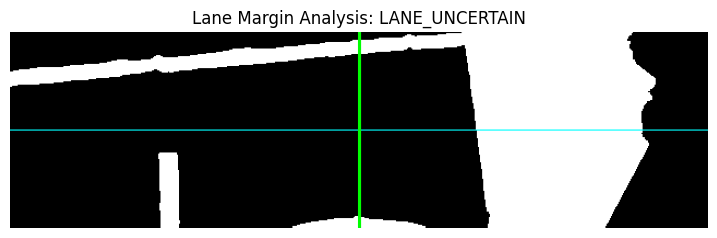

In [18]:
margin_vis = cv2.cvtColor(lane_mask, cv2.COLOR_GRAY2BGR)

reference_y = margin_result["reference_y"]
vehicle_x = mask_w // 2

# 측정 기준선
cv2.line(
    margin_vis,
    (0, reference_y),
    (mask_w - 1, reference_y),
    (255, 255, 0),
    1,
)

# 차량 중심
cv2.line(
    margin_vis,
    (vehicle_x, 0),
    (vehicle_x, mask_h - 1),
    (0, 255, 0),
    2,
)

if margin_result["left_lane_x"] is not None:
    left_x = int(margin_result["left_lane_x"])
    right_x = int(margin_result["right_lane_x"])

    # 왼쪽 차선
    cv2.circle(
        margin_vis,
        (left_x, reference_y),
        6,
        (255, 0, 0),
        -1,
    )

    # 오른쪽 차선
    cv2.circle(
        margin_vis,
        (right_x, reference_y),
        6,
        (0, 0, 255),
        -1,
    )

    # 좌우 여유 폭 표시
    cv2.line(
        margin_vis,
        (left_x, reference_y),
        (vehicle_x, reference_y),
        (255, 0, 0),
        3,
    )

    cv2.line(
        margin_vis,
        (vehicle_x, reference_y),
        (right_x, reference_y),
        (0, 0, 255),
        3,
    )

plt.figure(figsize=(9, 5))
plt.imshow(cv2.cvtColor(margin_vis, cv2.COLOR_BGR2RGB))
plt.title(
    f"Lane Margin Analysis: {margin_result['position_status']}"
)
plt.axis("off")
plt.show()

## 15. 전체 차량 상태 및 주의사항 반환

차선 이탈 상태, 진행 방향, 좌우 차선 여유 폭을 통합하여 최종 위험 단계와 운전자 주의사항을 생성한다.

위험 단계는 다음 세 단계로 구분한다.

- `NORMAL`: 정상 주행
- `CAUTION`: 차선 한쪽으로 편향되거나 차선에 근접
- `DANGER`: 차선 이탈 또는 차선 검출 실패

In [19]:
def determine_risk_and_advice(
    departure_status,
    heading_status,
    position_status,
):
    """
    개별 차선 분석 결과를 통합하여 위험 단계와 주의사항을 생성한다.
    """

    # 1. 차선 검출 실패
    if (
        position_status == "LANE_UNCERTAIN"
        or departure_status == "LANE_UNCERTAIN"
    ):
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "LANE_DETECTION_FAILED",
            "advice": "차선 인식이 불안정합니다. 분석 결과를 주의해서 확인하세요.",
        }

    # 2. 차선 이탈
    if departure_status == "LEFT_DEPARTURE":
        return {
            "risk_level": "DANGER",
            "vehicle_status": "LEFT_DEPARTURE",
            "advice": "왼쪽 차선을 이탈했습니다. 오른쪽으로 안전하게 복귀하세요.",
        }

    if departure_status == "RIGHT_DEPARTURE":
        return {
            "risk_level": "DANGER",
            "vehicle_status": "RIGHT_DEPARTURE",
            "advice": "오른쪽 차선을 이탈했습니다. 왼쪽으로 안전하게 복귀하세요.",
        }

    if position_status == "OUT_OF_LANE":
        return {
            "risk_level": "DANGER",
            "vehicle_status": "OUT_OF_LANE",
            "advice": "차량이 차선 범위를 벗어났습니다. 즉시 차선 안으로 복귀하세요.",
        }

    # 3. 차선 근접 또는 경고
    if departure_status == "LEFT_WARNING":
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "LEFT_WARNING",
            "advice": "차량이 왼쪽으로 치우쳤습니다. 오른쪽으로 완만하게 이동하세요.",
        }

    if departure_status == "RIGHT_WARNING":
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "RIGHT_WARNING",
            "advice": "차량이 오른쪽으로 치우쳤습니다. 왼쪽으로 완만하게 이동하세요.",
        }

    if position_status == "TOO_CLOSE_LEFT":
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "TOO_CLOSE_LEFT",
            "advice": "왼쪽 차선에 가깝습니다. 오른쪽으로 완만하게 이동하세요.",
        }

    if position_status == "TOO_CLOSE_RIGHT":
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "TOO_CLOSE_RIGHT",
            "advice": "오른쪽 차선에 가깝습니다. 왼쪽으로 완만하게 이동하세요.",
        }

    if position_status == "LEFT_BIASED":
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "LEFT_BIASED",
            "advice": "차량이 차선 왼쪽에 치우쳐 있습니다. 차선 중앙으로 이동하세요.",
        }

    if position_status == "RIGHT_BIASED":
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "RIGHT_BIASED",
            "advice": "차량이 차선 오른쪽에 치우쳐 있습니다. 차선 중앙으로 이동하세요.",
        }

    # 4. 급격한 도로 방향 변화
    if heading_status == "SHARP_LEFT":
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "SHARP_LEFT_CURVE",
            "advice": "급한 왼쪽 곡선 구간입니다. 속도를 줄이고 방향을 유지하세요.",
        }

    if heading_status == "SHARP_RIGHT":
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "SHARP_RIGHT_CURVE",
            "advice": "급한 오른쪽 곡선 구간입니다. 속도를 줄이고 방향을 유지하세요.",
        }

    # 5. 정상
    return {
        "risk_level": "NORMAL",
        "vehicle_status": "CENTERED",
        "advice": "정상적인 차선 유지 상태입니다.",
    }


final_state = determine_risk_and_advice(
    departure_status=departure_status,
    heading_status=heading_status,
    position_status=margin_result["position_status"],
)

print("최종 차량 상태")
print("위험 단계:", final_state["risk_level"])
print("차량 상태:", final_state["vehicle_status"])
print("주의사항:", final_state["advice"])

최종 차량 상태
위험 단계: CAUTION
차량 상태: LANE_DETECTION_FAILED
주의사항: 차선 인식이 불안정합니다. 분석 결과를 주의해서 확인하세요.


## 16. 차선 상태 분석 결과 통합

앞에서 계산한 차선 중심 오차, 진행 방향, 좌우 여유 폭 및 위험 판단 결과를 하나의 데이터 구조로 통합한다.

In [20]:
lane_analysis_result = {
    "vehicle_center_x": round(
        offset_result["vehicle_center_x"],
        1,
    ),

    "lane_center_x": (
        round(offset_result["lane_center_x"], 1)
        if offset_result["lane_center_x"] is not None
        else None
    ),

    "offset_px": (
        round(offset_result["offset_px"], 1)
        if offset_result["offset_px"] is not None
        else None
    ),

    "offset_ratio": (
        round(offset_result["offset_ratio"], 3)
        if offset_result["offset_ratio"] is not None
        else None
    ),

    "departure_status": departure_status,

    "heading_angle_deg": round(
        heading_angle_deg,
        2,
    ),
    "heading_status": heading_status,

    "left_lane_x": margin_result["left_lane_x"],
    "right_lane_x": margin_result["right_lane_x"],
    "lane_width_px": margin_result["lane_width_px"],
    "left_margin_px": margin_result["left_margin_px"],
    "right_margin_px": margin_result["right_margin_px"],
    "left_margin_ratio": margin_result["left_margin_ratio"],
    "right_margin_ratio": margin_result["right_margin_ratio"],
    "position_status": margin_result["position_status"],

    "risk_level": final_state["risk_level"],
    "vehicle_status": final_state["vehicle_status"],
    "advice": final_state["advice"],
}

lane_analysis_result 

{'vehicle_center_x': 320.0,
 'lane_center_x': None,
 'offset_px': None,
 'offset_ratio': None,
 'departure_status': 'LANE_UNCERTAIN',
 'heading_angle_deg': 1.0,
 'heading_status': 'STRAIGHT',
 'left_lane_x': None,
 'right_lane_x': None,
 'lane_width_px': None,
 'left_margin_px': None,
 'right_margin_px': None,
 'left_margin_ratio': None,
 'right_margin_ratio': None,
 'position_status': 'LANE_UNCERTAIN',
 'risk_level': 'CAUTION',
 'vehicle_status': 'LANE_DETECTION_FAILED',
 'advice': '차선 인식이 불안정합니다. 분석 결과를 주의해서 확인하세요.'}

## 17. 분석 결과 오버레이

차선 분석 결과를 원본 이미지 위에 시각화한다.

표시 정보:
- 차량 중심선
- 차선 중심선
- 차선 이탈 상태
- 진행 방향각
- 좌우 차선 여유 비율
- 위험 단계
- 주의사항

In [21]:
def draw_lane_analysis_overlay(
    image,
    analysis_result,
    center_x,
):
    """
    차선 상태 분석 결과를 원본 이미지 위에 표시한다.
    """

    output = image.copy()
    h, w = output.shape[:2]

    # 위험 단계별 표시 색상: BGR
    risk_colors = {
        "NORMAL": (0, 200, 0),
        "CAUTION": (0, 200, 255),
        "DANGER": (0, 0, 255),
    }

    risk_level = analysis_result["risk_level"]
    status_color = risk_colors.get(risk_level, (255, 255, 255))

    # BEV/ROI 좌표와 원본 이미지 좌표가 다르므로
    # 중심 위치는 비율로 원본 이미지 크기에 맞춰 변환
    lane_center_ratio = center_x / mask_w
    lane_center_original_x = int(lane_center_ratio * w)

    vehicle_center_x = w // 2

    # 차량 중심선
    cv2.line(
        output,
        (vehicle_center_x, h),
        (vehicle_center_x, int(h * 0.55)),
        (255, 0, 0),
        3,
    )

    # 검출된 차선 중심선
    cv2.line(
        output,
        (lane_center_original_x, h),
        (lane_center_original_x, int(h * 0.55)),
        (0, 255, 255),
        3,
    )

    # 상단 상태 패널
    overlay = output.copy()

    cv2.rectangle(
        overlay,
        (10, 10),
        (min(w - 10, 620), 245),
        (0, 0, 0),
        -1,
    )

    output = cv2.addWeighted(
        overlay,
        0.65,
        output,
        0.35,
        0,
    )

    def safe_percent(value):
        if value is None:
            return "N/A"
        return f"{value * 100:.1f}%"

    def safe_number(value, digits=1, suffix=""):
        if value is None:
            return "N/A"
        return f"{value:.{digits}f}{suffix}"

    text_lines = [
        f"Risk Level    : {analysis_result['risk_level']}",
        f"Vehicle State : {analysis_result['vehicle_status']}",
        f"Lane Status   : {analysis_result['departure_status']}",
        f"Offset        : {safe_number(analysis_result.get('offset_px'), 1, ' px')}",
        f"Heading       : {safe_number(analysis_result.get('heading_angle_deg'), 2, ' deg')}",
        f"Direction     : {analysis_result['heading_status']}",
        f"Left Margin   : {safe_percent(analysis_result['left_margin_ratio'])}",
        f"Right Margin  : {safe_percent(analysis_result['right_margin_ratio'])}",
    ]

    y = 40

    for index, text in enumerate(text_lines):
        color = status_color if index == 0 else (255, 255, 255)

        cv2.putText(
            output,
            text,
            (25, y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.58,
            color,
            2,
            cv2.LINE_AA,
        )

        y += 25

    # 화면 하단 위험 경고
    cv2.rectangle(
        output,
        (10, h - 55),
        (w - 10, h - 10),
        status_color,
        -1,
    )

    warning_text = analysis_result["advice"]

    # OpenCV 기본 글꼴은 한글을 표시하지 못하므로
    # 우선 영어 상태 문구를 영상에 출력
    english_advice = {
        "NORMAL": "Lane position is stable.",
        "CAUTION": "Caution: Return gently toward the lane center.",
        "DANGER": "Danger: Check the lane and correct the vehicle position.",
    }

    cv2.putText(
        output,
        english_advice.get(risk_level, warning_text),
        (25, h - 25),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.58,
        (0, 0, 0),
        2,
        cv2.LINE_AA,
    )

    # 차선 중심 보정 방향 표시
    offset_px = analysis_result.get("offset_px")

    if offset_px is None:
        correction = "LANE NOT DETECTED"
    elif abs(offset_px) < 1:
        correction = "KEEP CENTER"
    elif offset_px > 0:
        correction = "MOVE RIGHT"
    else:
        correction = "MOVE LEFT"

    cv2.putText(
        output,
        correction,
        (max(20, w - 220), 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.65,
        status_color,
        2,
        cv2.LINE_AA,
    )

    return output

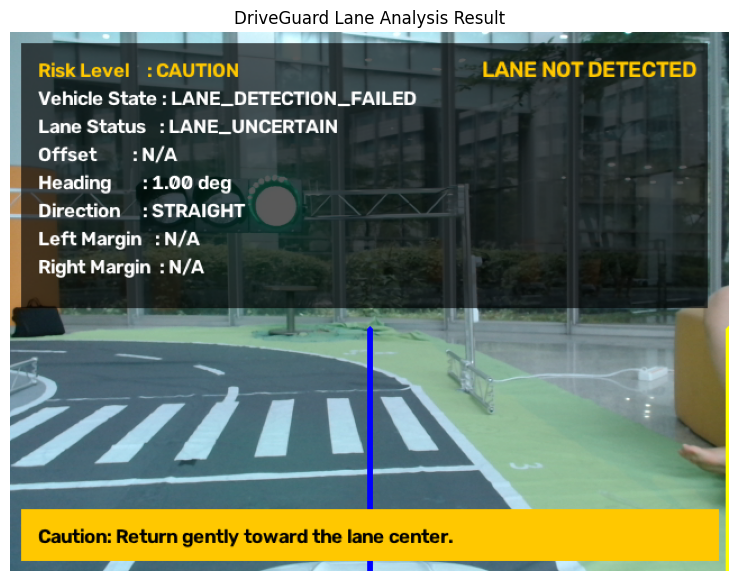

In [22]:
overlay_result = draw_lane_analysis_overlay(
    image=img,
    analysis_result=lane_analysis_result,
    center_x=center_x,
)

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(overlay_result, cv2.COLOR_BGR2RGB))
plt.title("DriveGuard Lane Analysis Result")
plt.axis("off")
plt.show()

## 18. 결과 이미지 저장

분석 결과가 표시된 이미지를 `outputs/images` 폴더에 저장한다.

In [23]:
OUTPUT_IMAGE_DIR = PROJECT_ROOT / "outputs" / "images"
OUTPUT_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

output_image_path = OUTPUT_IMAGE_DIR / "lane_analysis_sample01.jpg"

save_success = cv2.imwrite(
    str(output_image_path),
    overlay_result,
)

if not save_success:
    raise RuntimeError("결과 이미지를 저장하지 못했습니다.")

print("결과 이미지 저장 완료")
print("저장 경로:", output_image_path)

결과 이미지 저장 완료
저장 경로: C:\Users\shine\DriveGuard\outputs\images\lane_analysis_sample01.jpg


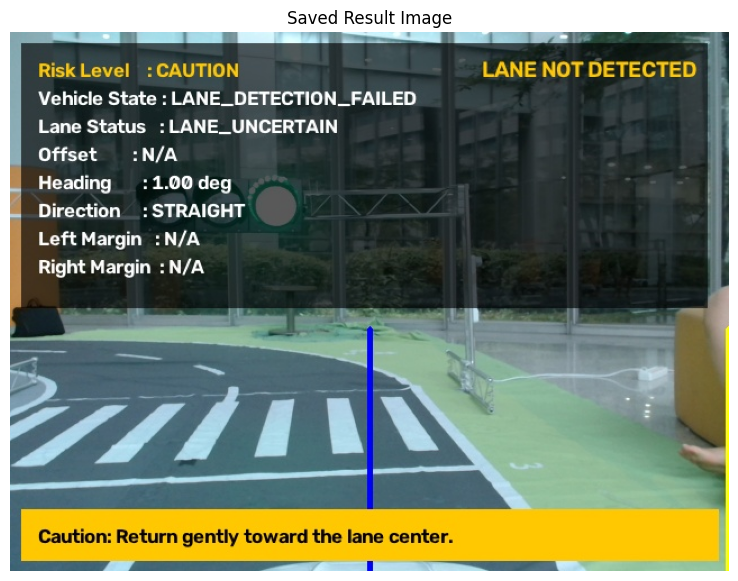

In [24]:
saved_image = cv2.imread(str(output_image_path))

if saved_image is None:
    raise FileNotFoundError(output_image_path)

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(saved_image, cv2.COLOR_BGR2RGB))
plt.title("Saved Result Image")
plt.axis("off")
plt.show()

## 19. 원본 블랙박스 프레임 차선·상대 속도 분석

영상 프레임을 BEV로 먼저 변환하지 않고 원본 시점에서 직접 처리한다.

1. 도로 ROI 설정
2. 흰색·노란색 차선 후보 검출
3. Canny + HoughLinesP로 좌우 차선 검출
4. 차선 중심·이탈·진행 방향 계산
5. Optical Flow로 프레임 간 움직임 지수 계산
6. 상대 속도를 `정지 / 저속 / 보통 / 고속`으로 분류

> 속도 결과는 실제 km/h가 아니라 영상 움직임 기반 상대 속도 상태이다.


In [25]:
def make_road_roi_mask(image_shape):
    """블랙박스 원본 영상에서 도로가 위치한 사다리꼴 ROI 마스크를 생성한다."""
    h, w = image_shape[:2]

    polygon = np.array([[
        (int(w * 0.08), int(h * 0.98)),
        (int(w * 0.42), int(h * 0.58)),
        (int(w * 0.58), int(h * 0.58)),
        (int(w * 0.92), int(h * 0.98)),
    ]], dtype=np.int32)

    mask = np.zeros((h, w), dtype=np.uint8)
    cv2.fillPoly(mask, polygon, 255)
    return mask, polygon


def build_lane_candidate_mask(frame):
    """HLS 색상 조건과 Canny 에지를 결합해 차선 후보 마스크를 만든다."""
    hls = cv2.cvtColor(frame, cv2.COLOR_BGR2HLS)

    # 흰색 차선: 밝기가 높고 채도가 지나치게 높지 않은 영역
    white_mask = cv2.inRange(
        hls,
        np.array([0, 165, 0], dtype=np.uint8),
        np.array([180, 255, 150], dtype=np.uint8),
    )

    # 노란색 차선
    yellow_mask = cv2.inRange(
        hls,
        np.array([10, 70, 70], dtype=np.uint8),
        np.array([40, 255, 255], dtype=np.uint8),
    )

    color_mask = cv2.bitwise_or(white_mask, yellow_mask)

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(gray, 50, 150)

    # 색상 후보 주변의 에지만 남기기 위해 후보를 약간 확장
    dilated_color = cv2.dilate(
        color_mask,
        np.ones((5, 5), np.uint8),
        iterations=1,
    )
    lane_edges = cv2.bitwise_and(edges, dilated_color)

    roi_mask, polygon = make_road_roi_mask(frame.shape)
    lane_edges = cv2.bitwise_and(lane_edges, roi_mask)

    lane_edges = cv2.morphologyEx(
        lane_edges,
        cv2.MORPH_CLOSE,
        np.ones((5, 5), np.uint8),
    )

    return lane_edges, color_mask, polygon


def _fit_lane_line(segments, y_top, y_bottom, frame_width):
    """검출된 여러 선분을 x = a*y + b 직선 하나로 결합한다."""
    if not segments:
        return None

    ys, xs, weights = [], [], []
    for x1, y1, x2, y2 in segments:
        length = float(np.hypot(x2 - x1, y2 - y1))
        ys.extend([y1, y2])
        xs.extend([x1, x2])
        weights.extend([length, length])

    if len(xs) < 4:
        return None

    try:
        a, b = np.polyfit(
            np.asarray(ys, dtype=float),
            np.asarray(xs, dtype=float),
            1,
            w=np.asarray(weights, dtype=float),
        )
    except Exception:
        return None

    x_top = int(np.clip(a * y_top + b, 0, frame_width - 1))
    x_bottom = int(np.clip(a * y_bottom + b, 0, frame_width - 1))

    return {
        "x_top": x_top,
        "y_top": int(y_top),
        "x_bottom": x_bottom,
        "y_bottom": int(y_bottom),
        "fit_a": float(a),
        "fit_b": float(b),
    }


def detect_lane_lines(frame, lane_edges):
    """Hough 선분을 왼쪽·오른쪽 차선으로 분류하고 대표 직선을 반환한다."""
    h, w = frame.shape[:2]
    center_x = w / 2.0
    y_top = int(h * 0.60)
    y_bottom = int(h * 0.97)

    min_line_length = max(35, int(w * 0.035))
    max_line_gap = max(50, int(w * 0.055))

    lines = cv2.HoughLinesP(
        lane_edges,
        rho=1,
        theta=np.pi / 180,
        threshold=35,
        minLineLength=min_line_length,
        maxLineGap=max_line_gap,
    )

    left_segments = []
    right_segments = []

    if lines is not None:
        for line in lines.reshape(-1, 4):
            x1, y1, x2, y2 = map(int, line)
            dx = x2 - x1
            dy = y2 - y1

            if dx == 0:
                continue

            slope = dy / dx
            abs_slope = abs(slope)
            midpoint_x = (x1 + x2) / 2.0

            # 수평선·지나치게 가파른 구조물 제거
            if abs_slope < 0.35 or abs_slope > 5.0:
                continue

            if slope < 0 and midpoint_x < center_x * 1.08:
                left_segments.append((x1, y1, x2, y2))
            elif slope > 0 and midpoint_x > center_x * 0.92:
                right_segments.append((x1, y1, x2, y2))

    left_line = _fit_lane_line(left_segments, y_top, y_bottom, w)
    right_line = _fit_lane_line(right_segments, y_top, y_bottom, w)

    return left_line, right_line, left_segments, right_segments



def estimate_relative_speed(frame):
    """
    프레임 간 Optical Flow로 영상 기반 상대 속도를 추정한다.

    Returns
    -------
    motion_index : float or None
        추적된 특징점의 중앙 이동량(px/frame)
    speed_status : str
        STOPPED / LOW / MEDIUM / HIGH / UNAVAILABLE
    tracked_points : int
        계산에 사용된 특징점 개수

    Notes
    -----
    이 값은 실제 km/h가 아니라 카메라 영상의 상대적인 움직임 수준이다.
    """
    global PREVIOUS_SPEED_GRAY, SPEED_HISTORY

    # 노트북 셀을 순서대로 실행하지 않았더라도 안전하게 초기화
    if "SPEED_HISTORY" not in globals() or SPEED_HISTORY is None:
        SPEED_HISTORY = deque(maxlen=7)

    if "PREVIOUS_SPEED_GRAY" not in globals():
        PREVIOUS_SPEED_GRAY = None

    h, w = frame.shape[:2]
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # 하늘, 건물, 앞차 영향을 줄이고 도로 하단 중심부만 사용
    roi_mask = np.zeros_like(gray)
    polygon = np.array([[
        (int(w * 0.12), int(h * 0.96)),
        (int(w * 0.38), int(h * 0.58)),
        (int(w * 0.62), int(h * 0.58)),
        (int(w * 0.88), int(h * 0.96)),
    ]], dtype=np.int32)
    cv2.fillPoly(roi_mask, polygon, 255)

    if PREVIOUS_SPEED_GRAY is None:
        PREVIOUS_SPEED_GRAY = gray
        return None, "UNAVAILABLE", 0

    previous_points = cv2.goodFeaturesToTrack(
        PREVIOUS_SPEED_GRAY,
        mask=roi_mask,
        maxCorners=180,
        qualityLevel=0.01,
        minDistance=12,
        blockSize=7,
    )

    if previous_points is None or len(previous_points) < 8:
        PREVIOUS_SPEED_GRAY = gray
        return None, "UNAVAILABLE", 0

    current_points, status, _ = cv2.calcOpticalFlowPyrLK(
        PREVIOUS_SPEED_GRAY,
        gray,
        previous_points,
        None,
        winSize=(21, 21),
        maxLevel=3,
        criteria=(
            cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT,
            30,
            0.01,
        ),
    )

    PREVIOUS_SPEED_GRAY = gray

    if current_points is None or status is None:
        return None, "UNAVAILABLE", 0

    valid = status.reshape(-1) == 1
    old_points = previous_points.reshape(-1, 2)[valid]
    new_points = current_points.reshape(-1, 2)[valid]

    if len(old_points) < 8:
        return None, "UNAVAILABLE", int(len(old_points))

    displacement = np.linalg.norm(new_points - old_points, axis=1)

    # 차량, 반사, 흔들림 등 이상치 영향 완화
    displacement = displacement[
        np.isfinite(displacement)
        & (displacement >= 0)
        & (displacement < 60)
    ]

    if len(displacement) < 8:
        return None, "UNAVAILABLE", int(len(displacement))

    raw_motion_index = float(np.median(displacement))
    SPEED_HISTORY.append(raw_motion_index)
    motion_index = float(np.mean(SPEED_HISTORY))

    # 영상별 해상도와 FPS에 따라 조정 가능한 상대 기준
    if motion_index < 0.7:
        speed_status = "STOPPED"
    elif motion_index < 2.0:
        speed_status = "LOW"
    elif motion_index < 4.5:
        speed_status = "MEDIUM"
    else:
        speed_status = "HIGH"

    return motion_index, speed_status, int(len(displacement))


def analyze_frame(frame):
    """원본 블랙박스 프레임 한 장을 분석한다."""
    global OFFSET_HISTORY, HEADING_HISTORY

    if "OFFSET_HISTORY" not in globals() or OFFSET_HISTORY is None:
        OFFSET_HISTORY = deque(maxlen=7)
    if "HEADING_HISTORY" not in globals() or HEADING_HISTORY is None:
        HEADING_HISTORY = deque(maxlen=7)

    if frame is None or frame.size == 0:
        raise ValueError("비어 있는 프레임입니다.")

    h, w = frame.shape[:2]
    vehicle_center_x = w / 2.0

    motion_index, speed_status, tracked_points = estimate_relative_speed(frame)

    lane_edges, color_mask, roi_polygon = build_lane_candidate_mask(frame)
    left_line, right_line, _, _ = detect_lane_lines(frame, lane_edges)

    reference_y = int(h * 0.90)

    if left_line is not None and right_line is not None:
        left_x = left_line["fit_a"] * reference_y + left_line["fit_b"]
        right_x = right_line["fit_a"] * reference_y + right_line["fit_b"]

        left_x = float(np.clip(left_x, 0, w - 1))
        right_x = float(np.clip(right_x, 0, w - 1))
        lane_width_px = right_x - left_x

        # 비현실적으로 좁거나 넓은 쌍은 잘못 매칭된 것으로 처리
        valid_lane_width = (w * 0.18) <= lane_width_px <= (w * 0.75)

        if valid_lane_width:
            lane_center_x = (left_x + right_x) / 2.0
            left_margin_px = vehicle_center_x - left_x
            right_margin_px = right_x - vehicle_center_x
            left_margin_ratio = left_margin_px / lane_width_px
            right_margin_ratio = right_margin_px / lane_width_px

            if left_margin_px <= 0 or right_margin_px <= 0:
                position_status = "OUT_OF_LANE"
            elif left_margin_ratio < 0.25:
                position_status = "TOO_CLOSE_LEFT"
            elif right_margin_ratio < 0.25:
                position_status = "TOO_CLOSE_RIGHT"
            elif abs(left_margin_ratio - right_margin_ratio) <= 0.10:
                position_status = "CENTERED"
            elif left_margin_ratio < right_margin_ratio:
                position_status = "LEFT_BIASED"
            else:
                position_status = "RIGHT_BIASED"

            frame_offset_result = calculate_lane_offset(
                center_x=lane_center_x,
                vehicle_center_x=vehicle_center_x,
                lane_width_px=lane_width_px,
            )

            # 중앙선의 위·아래 위치 차이로 도로 진행 방향 추정
            top_center_x = (
                left_line["x_top"] + right_line["x_top"]
            ) / 2.0
            bottom_center_x = (
                left_line["x_bottom"] + right_line["x_bottom"]
            ) / 2.0
            dy = max(1.0, left_line["y_bottom"] - left_line["y_top"])
            raw_heading_angle = float(
                np.degrees(np.arctan2(top_center_x - bottom_center_x, dy))
            )
        else:
            left_line = None
            right_line = None

    if left_line is None or right_line is None:
        lane_center_x = None
        lane_width_px = None
        left_margin_px = None
        right_margin_px = None
        left_margin_ratio = None
        right_margin_ratio = None
        position_status = "LANE_UNCERTAIN"
        raw_heading_angle = 0.0
        frame_offset_result = {
            "vehicle_center_x": vehicle_center_x,
            "lane_center_x": None,
            "offset_px": None,
            "offset_ratio": None,
        }

    # 최근 프레임 이동평균으로 상태 깜빡임 완화
    if frame_offset_result["offset_ratio"] is not None:
        OFFSET_HISTORY.append(frame_offset_result["offset_ratio"])
        smoothed_ratio = float(np.mean(OFFSET_HISTORY))
        frame_offset_result["offset_ratio"] = smoothed_ratio
        frame_offset_result["offset_px"] = smoothed_ratio * lane_width_px

    HEADING_HISTORY.append(raw_heading_angle)
    frame_heading_angle = float(np.mean(HEADING_HISTORY))

    frame_departure_status = determine_departure_status(
        frame_offset_result["offset_ratio"]
    )
    frame_heading_status = determine_heading_status(frame_heading_angle)

    frame_final_state = determine_risk_and_advice(
        departure_status=frame_departure_status,
        heading_status=frame_heading_status,
        position_status=position_status,
    )

    result = {
        "vehicle_center_x": round(vehicle_center_x, 1),
        "lane_center_x": (
            round(lane_center_x, 1) if lane_center_x is not None else None
        ),
        "offset_px": (
            round(frame_offset_result["offset_px"], 1)
            if frame_offset_result["offset_px"] is not None else None
        ),
        "offset_ratio": (
            round(frame_offset_result["offset_ratio"], 4)
            if frame_offset_result["offset_ratio"] is not None else None
        ),
        "departure_status": frame_departure_status,
        "heading_angle_deg": round(frame_heading_angle, 2),
        "heading_status": frame_heading_status,
        "motion_index": round(motion_index, 2) if motion_index is not None else None,
        "speed_status": speed_status,
        "speed_tracked_points": tracked_points,
        "left_lane_x": round(left_x, 1) if left_line is not None else None,
        "right_lane_x": round(right_x, 1) if right_line is not None else None,
        "lane_width_px": round(lane_width_px, 1) if lane_width_px is not None else None,
        "left_margin_px": round(left_margin_px, 1) if left_margin_px is not None else None,
        "right_margin_px": round(right_margin_px, 1) if right_margin_px is not None else None,
        "left_margin_ratio": left_margin_ratio,
        "right_margin_ratio": right_margin_ratio,
        "position_status": position_status,
        "risk_level": frame_final_state["risk_level"],
        "vehicle_status": frame_final_state["vehicle_status"],
        "advice": frame_final_state["advice"],
        "left_line": left_line,
        "right_line": right_line,
        "roi_polygon": roi_polygon[0].tolist(),
    }

    output = draw_video_overlay(
        image=frame,
        analysis_result=result,
    )

    return output, result, lane_edges


## 20. 원본 영상 분석 결과 오버레이

검출된 좌·우 차선, 차선 중심, 차량 중심, 위험 단계, 진행 방향과 상대 속도 상태를 원본 영상 위에 표시한다.

- 초록색: 검출된 좌·우 차선
- 파란색: 차량 기준 중심
- 노란색: 검출된 차선 중심
- 상대 속도: Optical Flow 기반 `정지 / 저속 / 보통 / 고속`


In [26]:
def draw_korean_text(
    image,
    text,
    position,
    font_size=28,
    color=(255, 255, 255),
):
    """Pillow와 Windows 맑은 고딕을 이용해 OpenCV 이미지에 한글을 출력한다."""
    font_path = "C:/Windows/Fonts/malgun.ttf"

    if not Path(font_path).exists():
        raise FileNotFoundError(
            f"한글 글꼴을 찾을 수 없습니다: {font_path}"
        )

    rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    pil_image = Image.fromarray(rgb_image)
    draw = ImageDraw.Draw(pil_image)
    font = ImageFont.truetype(font_path, font_size)
    rgb_color = (color[2], color[1], color[0])
    draw.text(position, text, font=font, fill=rgb_color)

    return cv2.cvtColor(np.array(pil_image), cv2.COLOR_RGB2BGR)


def draw_video_overlay(image, analysis_result):
    """원본 영상에 검출 차선과 한글 분석 패널을 표시한다."""
    original_h, original_w = image.shape[:2]
    crop_top = int(original_h * DISPLAY_CROP_TOP_RATIO)

    output = image[crop_top:, :].copy()
    h, w = output.shape[:2]

    risk_colors = {
        "NORMAL": (0, 180, 0),
        "CAUTION": (0, 190, 255),
        "DANGER": (0, 0, 230),
    }
    risk_level = analysis_result["risk_level"]
    status_color = risk_colors.get(risk_level, (255, 255, 255))

    def cropped_point(x, y):
        return int(x), int(y - crop_top)

    # 도로 ROI 경계는 얇게 표시
    roi_polygon = analysis_result.get("roi_polygon")
    if roi_polygon:
        polygon = np.array([
            [cropped_point(x, y) for x, y in roi_polygon]
        ], dtype=np.int32)
        cv2.polylines(output, polygon, True, (120, 120, 120), 2)

    # 실제 검출된 차선만 표시
    for key in ["left_line", "right_line"]:
        line = analysis_result.get(key)
        if line is not None:
            p1 = cropped_point(line["x_bottom"], line["y_bottom"])
            p2 = cropped_point(line["x_top"], line["y_top"])
            cv2.line(output, p1, p2, (0, 255, 0), 7, cv2.LINE_AA)

    vehicle_center_x = int(analysis_result["vehicle_center_x"])
    cv2.line(
        output,
        (vehicle_center_x, h - 1),
        (vehicle_center_x, int(h * 0.58)),
        (255, 0, 0),
        4,
    )

    lane_center_x = analysis_result.get("lane_center_x")
    if lane_center_x is not None:
        lane_center_x = int(lane_center_x)
        cv2.line(
            output,
            (lane_center_x, h - 1),
            (lane_center_x, int(h * 0.58)),
            (0, 255, 255),
            4,
        )

    panel_width = int(w * 0.40)
    panel_height = min(int(h * 0.66), 485)
    panel = output.copy()
    cv2.rectangle(panel, (20, 20), (panel_width, panel_height), (0, 0, 0), -1)
    output = cv2.addWeighted(panel, 0.78, output, 0.22, 0)

    def percent_text(value):
        return "측정 불가" if value is None else f"{value * 100:.1f}%"

    risk_korean = {"NORMAL": "정상", "CAUTION": "주의", "DANGER": "위험"}
    departure_korean = {
        "NORMAL": "정상",
        "LEFT_WARNING": "왼쪽 편향 주의",
        "RIGHT_WARNING": "오른쪽 편향 주의",
        "LEFT_DEPARTURE": "왼쪽 차선 이탈",
        "RIGHT_DEPARTURE": "오른쪽 차선 이탈",
        "LANE_UNCERTAIN": "차선 인식 불안정",
    }
    heading_korean = {
        "STRAIGHT": "직진",
        "LEFT": "왼쪽 진행",
        "RIGHT": "오른쪽 진행",
        "SHARP_LEFT": "급한 왼쪽 방향",
        "SHARP_RIGHT": "급한 오른쪽 방향",
    }
    speed_korean = {
        "STOPPED": "정지",
        "LOW": "저속",
        "MEDIUM": "보통",
        "HIGH": "고속",
        "UNAVAILABLE": "측정 준비",
    }
    status_korean = {
        "CENTERED": "차선 중앙",
        "LEFT_WARNING": "왼쪽 편향",
        "RIGHT_WARNING": "오른쪽 편향",
        "TOO_CLOSE_LEFT": "왼쪽 차선 근접",
        "TOO_CLOSE_RIGHT": "오른쪽 차선 근접",
        "LEFT_BIASED": "왼쪽으로 치우침",
        "RIGHT_BIASED": "오른쪽으로 치우침",
        "LEFT_DEPARTURE": "왼쪽 차선 이탈",
        "RIGHT_DEPARTURE": "오른쪽 차선 이탈",
        "OUT_OF_LANE": "차선 범위 이탈",
        "LANE_DETECTION_FAILED": "차선 인식 불안정",
        "SHARP_LEFT_CURVE": "급한 왼쪽 곡선",
        "SHARP_RIGHT_CURVE": "급한 오른쪽 곡선",
    }

    lines = [
        ("위험 단계", risk_korean.get(risk_level, risk_level)),
        ("차량 상태", status_korean.get(analysis_result["vehicle_status"], analysis_result["vehicle_status"])),
        ("차선 상태", departure_korean.get(analysis_result["departure_status"], analysis_result["departure_status"])),
        ("중심 오차", f"{analysis_result['offset_px']:.1f} px" if analysis_result["offset_px"] is not None else "측정 불가"),
        ("진행 방향각", f"{analysis_result['heading_angle_deg']:.2f}°"),
        ("진행 방향", heading_korean.get(analysis_result["heading_status"], analysis_result["heading_status"])),
        ("상대 속도", speed_korean.get(analysis_result.get("speed_status"), analysis_result.get("speed_status", "측정 불가"))),
        ("움직임 지수", f"{analysis_result['motion_index']:.2f} px/frame" if analysis_result.get("motion_index") is not None else "측정 준비"),
        ("왼쪽 여유", percent_text(analysis_result["left_margin_ratio"])),
        ("오른쪽 여유", percent_text(analysis_result["right_margin_ratio"])),
    ]

    y = 42
    for index, (label, value) in enumerate(lines):
        color = status_color if index == 0 else (255, 255, 255)
        output = draw_korean_text(
            output,
            f"{label} : {value}",
            (40, y),
            font_size=28,
            color=color,
        )
        y += 41

    offset_px = analysis_result["offset_px"]
    if offset_px is None:
        correction = "차선 인식 확인"
    elif abs(offset_px) < 5:
        correction = "차선 중앙 유지"
    elif offset_px > 0:
        correction = "오른쪽으로 이동"
    else:
        correction = "왼쪽으로 이동"

    output = draw_korean_text(
        output,
        correction,
        (max(20, w - 360), 35),
        font_size=38,
        color=status_color,
    )

    cv2.rectangle(output, (20, h - 85), (w - 20, h - 20), status_color, -1)
    output = draw_korean_text(
        output,
        analysis_result["advice"],
        (45, h - 78),
        font_size=33,
        color=(0, 0, 0),
    )

    return output


## 21. 입력 영상 설정

기존 실습 저장소에 포함된 `driving_simulation.mp4`를 검색하여 입력 영상으로 사용한다.

In [27]:
input_video_path = (
    PROJECT_ROOT
    / "data"
    / "videos"
    / "test2.mp4"
)

if not input_video_path.exists():
    raise FileNotFoundError(
        f"입력 영상을 찾을 수 없습니다: {input_video_path}"
    )

print("입력 영상:", input_video_path)

입력 영상: C:\Users\shine\DriveGuard\data\videos\test2.mp4


In [28]:
cap = cv2.VideoCapture(str(input_video_path))

if not cap.isOpened():
    raise RuntimeError(
        f"영상을 열 수 없습니다: {input_video_path}"
    )

video_fps = cap.get(cv2.CAP_PROP_FPS)
video_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
video_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
video_frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

cap.release()

video_duration = (
    video_frame_count / video_fps
    if video_fps > 0
    else 0
)

print("FPS:", video_fps)
print("해상도:", video_width, "x", video_height)
print("전체 프레임:", video_frame_count)
print(f"영상 길이: {video_duration:.2f}초")

FPS: 30.0
해상도: 1920 x 1080
전체 프레임: 622
영상 길이: 20.73초


## 보충: 원본 프레임에서 ROI·차선 후보·검출 직선 확인

전체 영상을 처리하기 전에 첫 프레임 한 장에서 다음 결과를 확인한다.

- 회색 사다리꼴: 도로 ROI
- 흑백 화면: 색상 조건과 Canny로 만든 차선 후보
- 초록색 선: Hough 변환으로 검출한 좌·우 차선


In [29]:
cap = cv2.VideoCapture(str(input_video_path))

ret, test_frame = cap.read()
cap.release()

if not ret:
    raise RuntimeError("첫 프레임을 읽지 못했습니다.")

test_h, test_w = test_frame.shape[:2]

print("영상 크기:", test_w, "x", test_h)

영상 크기: 1920 x 1080


C:\Users\shine\miniconda3\envs\driveguard\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\shine\miniconda3\envs\driveguard\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\shine\miniconda3\envs\driveguard\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 54532 (\N{HANGUL SYLLABLE PEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\shine\miniconda3\envs\driveguard\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 47112 (\N{HANGUL SYLLABLE RE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\shine\miniconda3\envs\driveguard\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51076 (\N{HAN

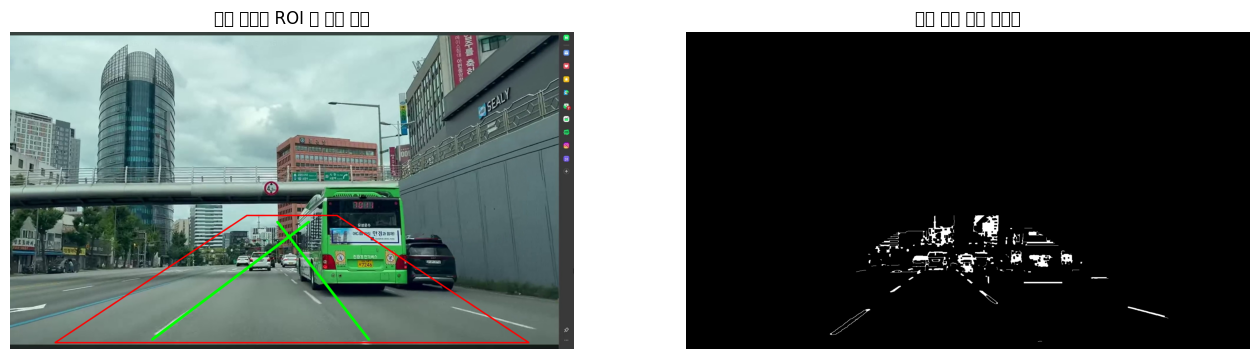

왼쪽 차선 검출: True
오른쪽 차선 검출: True


In [30]:
lane_edges_test, color_mask_test, roi_polygon_test = build_lane_candidate_mask(
    test_frame
)
left_test, right_test, _, _ = detect_lane_lines(
    test_frame,
    lane_edges_test,
)

debug_frame = test_frame.copy()
cv2.polylines(
    debug_frame,
    roi_polygon_test,
    True,
    (0, 0, 255),
    4,
)

for line in [left_test, right_test]:
    if line is not None:
        cv2.line(
            debug_frame,
            (line["x_bottom"], line["y_bottom"]),
            (line["x_top"], line["y_top"]),
            (0, 255, 0),
            7,
            cv2.LINE_AA,
        )

plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(debug_frame, cv2.COLOR_BGR2RGB))
plt.title("원본 프레임 ROI 및 검출 차선")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lane_edges_test, cmap="gray")
plt.title("차선 후보 에지 마스크")
plt.axis("off")

plt.show()

print("왼쪽 차선 검출:", left_test is not None)
print("오른쪽 차선 검출:", right_test is not None)


## 22. 전체 영상 분석 및 저장

입력 영상을 프레임 단위로 분석하고 다음 결과를 저장한다.

- 차선 상태와 상대 속도가 표시된 MP4 영상
- 프레임별 차선·위험도·움직임 지수·상대 속도 CSV


In [31]:
OUTPUT_VIDEO_DIR = PROJECT_ROOT / "outputs" / "videos"
OUTPUT_VIDEO_DIR.mkdir(parents=True, exist_ok=True)

def reset_runtime_state():
    """새 영상을 처리하기 전에 이동평균·Optical Flow 상태를 초기화한다."""
    global PREVIOUS_SPEED_GRAY, OFFSET_HISTORY, HEADING_HISTORY, SPEED_HISTORY

    if "OFFSET_HISTORY" not in globals() or OFFSET_HISTORY is None:
        OFFSET_HISTORY = deque(maxlen=7)
    else:
        OFFSET_HISTORY.clear()

    if "HEADING_HISTORY" not in globals() or HEADING_HISTORY is None:
        HEADING_HISTORY = deque(maxlen=7)
    else:
        HEADING_HISTORY.clear()

    if "SPEED_HISTORY" not in globals() or SPEED_HISTORY is None:
        SPEED_HISTORY = deque(maxlen=7)
    else:
        SPEED_HISTORY.clear()

    PREVIOUS_SPEED_GRAY = None


reset_runtime_state()

output_video_path = (
    OUTPUT_VIDEO_DIR / "result_test2.mp4"
)

output_csv_path = (
    OUTPUT_VIDEO_DIR / "driveguard_frame_results_test2.csv"
)

cap = cv2.VideoCapture(str(input_video_path))

if not cap.isOpened():
    raise RuntimeError("입력 영상을 열지 못했습니다.")

fps = cap.get(cv2.CAP_PROP_FPS)

if fps <= 0:
    fps = 20.0

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

crop_top = int(
    height * DISPLAY_CROP_TOP_RATIO
)

output_height = height - crop_top

writer = cv2.VideoWriter(
    str(output_video_path),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, output_height),
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("결과 영상 Writer 생성 실패")

frame_records = []

frame_index = 0
success_count = 0
failure_count = 0

while True:
    ret, frame = cap.read()

    if not ret:
        break

    time_sec = frame_index / fps

    try:
        analyzed_frame, result, _ = analyze_frame(frame)

        result_record = {
            "frame": frame_index,
            "time_sec": round(time_sec, 3),
            **result,
            "analysis_success": True,
        }

        success_count += 1

    except Exception as error:
        crop_top = int(
            frame.shape[0] * DISPLAY_CROP_TOP_RATIO
        )

        analyzed_frame = frame[crop_top:, :].copy()

        # 분석 실패 프레임 표시
        cv2.rectangle(
            analyzed_frame,
            (10, 10),
            (width - 10, 65),
            (0, 0, 255),
            -1,
        )

        cv2.putText(
            analyzed_frame,
            "LANE ANALYSIS FAILED",
            (25, 48),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.85,
            (255, 255, 255),
            2,
            cv2.LINE_AA,
        )

        result_record = {
            "frame": frame_index,
            "time_sec": round(time_sec, 3),
            "analysis_success": False,
            "error": str(error),
        }

        failure_count += 1

    writer.write(analyzed_frame)
    frame_records.append(result_record)

    frame_index += 1

    # 진행 상황 출력
    if frame_index % 100 == 0:
        print(
            f"{frame_index}/{total_frames} 프레임 처리 완료"
        )

cap.release()
writer.release()

results_df = pd.DataFrame(frame_records)
results_df.to_csv(
    output_csv_path,
    index=False,
    encoding="utf-8-sig",
)

print()
print("영상 분석 완료")
print("성공 프레임:", success_count)
print("실패 프레임:", failure_count)
print("결과 영상:", output_video_path)
print("결과 CSV:", output_csv_path)


100/622 프레임 처리 완료
200/622 프레임 처리 완료
300/622 프레임 처리 완료
400/622 프레임 처리 완료
500/622 프레임 처리 완료
600/622 프레임 처리 완료

영상 분석 완료
성공 프레임: 607
실패 프레임: 15
결과 영상: C:\Users\shine\DriveGuard\outputs\videos\result_test2.mp4
결과 CSV: C:\Users\shine\DriveGuard\outputs\videos\driveguard_frame_results_test2.csv


## 23. 결과 영상 열기

FFmpeg 없이도 Windows 기본 동영상 플레이어에서 결과 파일을 직접 연다.


In [32]:
import os

if not output_video_path.exists():
    raise FileNotFoundError(
        f"결과 영상이 없습니다: {output_video_path}"
    )

print("결과 영상 경로:", output_video_path)
os.startfile(str(output_video_path))


결과 영상 경로: C:\Users\shine\DriveGuard\outputs\videos\result_test2.mp4
